# PCA Analysis of the Phase Transition in the 2D Ising Model

**Course:** PHY502 — Data Science and Statistical Physics
**Author:** Prakhar Shukla (23174029), IIT (BHU) Varanasi

This notebook is both the project and a study guide. Every section follows the same pattern: the **concept** is explained first, then the **code** implements it, then the **figure** shows the result, and finally a short **"What to notice"** paragraph interprets it. All figures are also saved to `figures/` so they can be dropped straight into slides.

### Roadmap

| § | Topic | Question it serves |
|---|---|---|
| 1 | The Ising model and its phase transition | background |
| 2 | Metropolis Monte Carlo: how the data are generated | data generation |
| 3 | What the configurations look like across $T_c$ | Q1 |
| 4 | PCA: the theory, built from scratch | method |
| 5 | Principal components of the Ising data | Q2, Q3 |
| 6 | PCA across the phase transition: $f_1(T)$, $f_2(T)$, $P(z_1)$, scatter plots | Q3, Q4 |
| 7 | Conventional observables: $\langle|m|\rangle$, $\chi$ | Q5 |
| 8 | Finite-size analysis and estimating $T_c$ from PCA alone | Q6 |
| 9 | Answers to the six project questions | summary |
| 10 | Limitations, extensions, slide outline and viva questions | presentation |

**Running it:** the simulation for four lattice sizes takes about 5 minutes on a laptop with NumPy alone. Results are cached in `data/`, so re-running the notebook afterwards is fast.

In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm, ListedColormap
from scipy.special import ellipk
from sklearn.decomposition import PCA as SkPCA
from sklearn.cluster import KMeans

os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)

# ---------- one consistent visual style for every figure ----------
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, GRID, AXIS = "#fcfcfb", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
RED, VIOLET = "#e34948", "#6250d6"
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "text.color": INK, "legend.frameon": False, "legend.fontsize": 9.5,
    "lines.linewidth": 2, "lines.markersize": 5, "figure.dpi": 110,
    "axes.prop_cycle": mpl.cycler(color=[BLUE, ORANGE, AQUA, YELLOW, "#e87ba4", "#008300", VIOLET, RED]),
})

TC = 2.0 / np.log(1.0 + np.sqrt(2.0))          # Onsager's exact critical temperature
print(f"Exact Tc = {TC:.6f}")

# Temperature colour scale: blue (ordered, T<Tc) -> grey (Tc) -> red (disordered, T>Tc)
TEMP_CMAP = LinearSegmentedColormap.from_list("temp", ["#104281", "#3987e5", "#a9a8a2", "#e66767", "#a32a2a"])
TEMP_NORM = TwoSlopeNorm(vmin=1.0, vcenter=TC, vmax=3.5)
SPIN_CMAP = ListedColormap(["#e34948", "#2a78d6"])     # -1 = red, +1 = blue
SIZE_COLORS = {10: "#86b6ef", 20: "#3987e5", 30: "#1c5cab", 40: "#0d366b"}   # ordinal ramp

def tc_line(ax, label=True):
    ax.axvline(TC, color=MUTED, lw=1.2, ls="--", zorder=0)
    if label:
        ax.text(TC, 0.015, r" $T_c$", transform=ax.get_xaxis_transform(), color=INK2, fontsize=9, va="bottom", ha="left")

def save(fig, name):
    fig.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")

Exact Tc = 2.269185


## 1. The Ising model and its phase transition

### 1.1 The model
Each site of an $N\times N$ square lattice carries a spin $s_{ij}=\pm1$. The energy of a configuration $\mathbf s$ is

$$H(\mathbf s) = -J\sum_{\langle ij,kl\rangle} s_{ij}\,s_{kl},\qquad J=1,$$

where the sum runs over nearest-neighbour pairs, each counted once. Aligned neighbours lower the energy by $J$; anti-aligned neighbours raise it. We use **periodic boundary conditions** (the lattice is a torus), which removes edges so that every site is equivalent — a property we will exploit in §5.

### 1.2 Statistical mechanics in one paragraph
At temperature $T$ (with $k_B=1$, so $\beta=1/T$) the probability of finding the system in configuration $\mathbf s$ is the **Boltzmann distribution**

$$P(\mathbf s)=\frac{e^{-\beta H(\mathbf s)}}{Z},\qquad Z=\sum_{\mathbf s}e^{-\beta H(\mathbf s)}.$$

Two forces compete. **Energy** favours alignment (all spins up or all down). **Entropy** favours disorder, because there are vastly more disordered configurations than ordered ones. Low $T$ lets energy win; high $T$ lets entropy win.

### 1.3 The order parameter and the transition
The **magnetisation per spin** $m=\frac{1}{N^2}\sum_{ij}s_{ij}$ measures how ordered the system is. In the infinite lattice:

- for $T<T_c$, $|m|>0$: the system spontaneously picks one of two ordered states, $+m$ or $-m$ (**spontaneous symmetry breaking** — $H$ is unchanged by flipping every spin, yet the state is not);
- for $T>T_c$, $m=0$: the disordered paramagnet.

Onsager (1944) solved the model exactly. The critical temperature is $T_c = 2/\ln(1+\sqrt2)\approx 2.269$, and below it the spontaneous magnetisation is $m_0(T)=\left[1-\sinh^{-4}(2/T)\right]^{1/8}$. These exact results let us **validate** our simulation.

### 1.4 Why the transition is interesting
At $T_c$ the **correlation length** $\xi$ — the typical size of aligned clusters — diverges, so fluctuations occur on every length scale. The **susceptibility** $\chi$ (how strongly $m$ responds to a field, equivalently how much $m$ fluctuates) diverges too. In a finite $N\times N$ lattice nothing truly diverges: $\xi$ is capped at $\sim N$, peaks become rounded and shift slightly. This is the **finite-size effect**, and §8 turns it into a tool.

### 1.5 The project's question
Every configuration is a point in a 400-dimensional space (for $N=20$). Can an **unsupervised** method, PCA, which knows nothing about physics, energy or temperature, discover that these points reorganise at $T_c$?

## 2. Generating the data: Metropolis Monte Carlo

### 2.1 Why we must sample
A $20\times20$ lattice has $2^{400}\approx10^{120}$ configurations, so $Z$ cannot be summed directly. Instead we draw a large set of configurations **distributed according to** $P(\mathbf s)$ and compute averages over them. This is **importance sampling**: we only visit the configurations that actually matter at a given $T$.

### 2.2 Markov chains and detailed balance
We build a random walk $\mathbf s^{(0)}\to\mathbf s^{(1)}\to\cdots$ whose long-run distribution is $P(\mathbf s)$. A sufficient condition is **detailed balance**:

$$P(\mathbf s)\,W(\mathbf s\to\mathbf s') = P(\mathbf s')\,W(\mathbf s'\to\mathbf s),$$

together with **ergodicity** (every configuration can be reached). Detailed balance says that, in equilibrium, the flow of probability from $\mathbf s$ to $\mathbf s'$ equals the reverse flow.

### 2.3 The Metropolis rule
1. Pick a spin $s_i$ and propose flipping it.
2. Compute the energy change. If $h_i$ is the sum of its four neighbours, $\Delta E = 2\,s_i\,h_i$, which can only be $-8,-4,0,4,8$.
3. Accept the flip with probability $\min\!\left(1,e^{-\beta\Delta E}\right)$.

Downhill moves are always accepted; uphill moves are accepted with the Boltzmann factor. Substituting into the detailed-balance condition shows it is satisfied exactly, since $P(\mathbf s')/P(\mathbf s)=e^{-\beta\Delta E}$.

### 2.4 The checkerboard trick
Colour the lattice like a chessboard. Every neighbour of a black site is white, so all black spins can be updated **simultaneously** — each sees a fixed local field. One **sweep** (one attempted flip per spin) is then: update all black sites, then all white sites. This lets NumPy update an entire lattice, for every temperature and many independent chains, in a single vectorised operation.

### 2.5 Three practical issues
- **Equilibration (burn-in).** The chain starts from an arbitrary configuration; early samples are not yet distributed according to $P(\mathbf s)$ and must be discarded.
- **Autocorrelation.** Successive configurations are similar, so they are not independent samples. We keep one configuration every 20 sweeps and run 20 independent chains per temperature.
- **Broken ergodicity at low $T$.** Below $T_c$ a single chain stays in the $+m$ or $-m$ state essentially forever, since reversing the whole lattice requires crossing a barrier that grows with $N$. The true Boltzmann distribution is symmetric, so we start each chain fully ordered with a **random sign**. This restores the symmetry across chains and, as §6.2 shows, is essential for PCA.

In [2]:
def local_field(s):
    '''Sum of the four nearest neighbours of every site (periodic boundaries).
    s has shape (..., N, N); the last two axes are the lattice.'''
    return (np.roll(s, 1, axis=-1) + np.roll(s, -1, axis=-1)
            + np.roll(s, 1, axis=-2) + np.roll(s, -1, axis=-2))

def checkerboard_masks(N):
    i, j = np.indices((N, N))
    black = (i + j) % 2 == 0
    return black, ~black

def metropolis_sweep(s, beta, masks, rng):
    '''One sweep. s: (n_T, n_chains, N, N) int8, updated in place. beta: (n_T,1,1,1).'''
    for mask in masks:                          # black sites, then white sites
        dE = 2.0 * s * local_field(s)           # energy change for flipping each spin
        accept = rng.random(s.shape) < np.exp(-beta * dE)
        s[accept & mask] *= -1
    return s

def simulate(N, temps, n_chains=20, n_equil=3000, n_samples=50, sample_every=20, seed=0):
    '''Returns configs of shape (n_T, n_chains*n_samples, N*N), dtype int8.
    Each chain starts fully ordered with a random sign (see section 2.5).'''
    rng = np.random.default_rng(seed)
    nT = len(temps)
    beta = (1.0 / np.asarray(temps, float)).reshape(nT, 1, 1, 1)
    masks = checkerboard_masks(N)
    signs = rng.choice(np.array([-1, 1], dtype=np.int8), size=(nT, n_chains, 1, 1))
    s = np.ones((nT, n_chains, N, N), dtype=np.int8) * signs
    for _ in range(n_equil):                    # burn-in, discarded
        metropolis_sweep(s, beta, masks, rng)
    out = np.empty((nT, n_chains, n_samples, N * N), dtype=np.int8)
    for k in range(n_samples):
        for _ in range(sample_every):
            metropolis_sweep(s, beta, masks, rng)
        out[:, :, k, :] = s.reshape(nT, n_chains, N * N)
    return out.reshape(nT, n_chains * n_samples, N * N)

def energy_per_spin(configs, N):
    s = configs.reshape(*configs.shape[:-1], N, N).astype(np.int32)
    return -(s * np.roll(s, 1, -1) + s * np.roll(s, 1, -2)).sum(axis=(-1, -2)) / N**2

def onsager_m(T):
    T = np.asarray(T, float); m = np.zeros_like(T); b = T < TC
    m[b] = (1 - np.sinh(2 / T[b]) ** -4) ** 0.125
    return m

def onsager_energy(T):
    '''Exact internal energy per spin of the infinite lattice.'''
    b = 1.0 / np.asarray(T, float)
    k = 2 * np.sinh(2 * b) / np.cosh(2 * b) ** 2
    return -1 / np.tanh(2 * b) * (1 + 2 / np.pi * (2 * np.tanh(2 * b) ** 2 - 1) * ellipk(k ** 2))

def tau_int(x, c=5.0):
    '''Integrated autocorrelation time (Sokal's automatic windowing).'''
    x = np.asarray(x, float) - np.mean(x); n = len(x)
    f = np.fft.rfft(x, 2 * n); acf = np.fft.irfft(f * np.conj(f))[:n]; acf /= acf[0]
    tau = 0.5
    for w in range(1, n):
        tau += acf[w]
        if w >= c * tau: break
    return tau, acf

### 2.6 Seeing equilibration
Below we run $N=40$ lattices from two starting points: **cold** (all spins up) and **hot** (random spins), and record $m$ after every sweep.

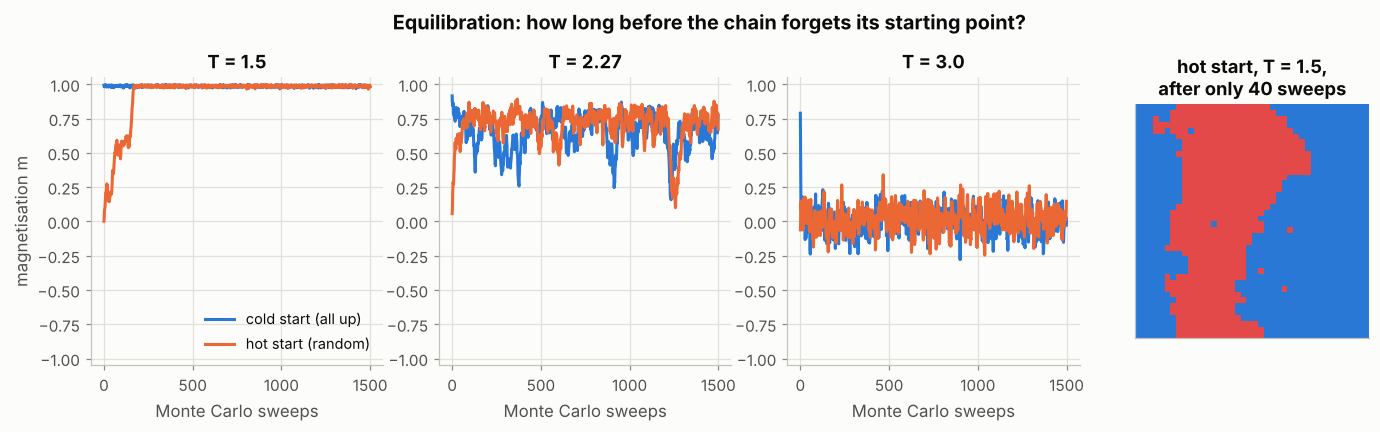

In [3]:
rng = np.random.default_rng(7)
N_demo, T_demo, n_sw = 40, np.array([1.5, 2.27, 3.0]), 1500
beta = (1 / T_demo).reshape(3, 1, 1, 1)
s = np.ones((3, 2, N_demo, N_demo), dtype=np.int8)
s[:, 1] = rng.choice(np.array([-1, 1], dtype=np.int8), size=(3, N_demo, N_demo))   # hot start
masks = checkerboard_masks(N_demo)
trace = np.empty((n_sw, 3, 2))
for t in range(n_sw):
    metropolis_sweep(s, beta, masks, rng)
    trace[t] = s.mean(axis=(-1, -2))
    if t == 39: hot_low_T_early = s[0, 1].copy()       # snapshot during coarsening

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), gridspec_kw={"width_ratios": [1, 1, 1, 0.8]})
for k, (ax, T) in enumerate(zip(axes, T_demo)):
    ax.plot(trace[:, k, 0], color=BLUE, label="cold start (all up)")
    ax.plot(trace[:, k, 1], color=ORANGE, label="hot start (random)")
    ax.set(title=f"T = {T}", xlabel="Monte Carlo sweeps", ylim=(-1.05, 1.05))
axes[0].set_ylabel("magnetisation m"); axes[0].legend(loc="lower right")
axes[3].imshow(hot_low_T_early, cmap=SPIN_CMAP, vmin=-1, vmax=1)
axes[3].set(title="hot start, T = 1.5,\nafter only 40 sweeps", xticks=[], yticks=[]); axes[3].grid(False)
fig.suptitle("Equilibration: how long before the chain forgets its starting point?", y=1.06, fontsize=13, fontweight="bold")
save(fig, "01_equilibration"); plt.show()

**What to notice.** At $T=3.0$ both starts reach the same fluctuating state within a few tens of sweeps. At $T=2.27$ the fluctuations are enormous and slow — this is **critical slowing down**. At $T=1.5$ the hot start needs well over a hundred sweeps: it first forms competing domains of both signs (right panel), which coarsen slowly until one sign takes over; its magnetisation climbs in steps as domains disappear. Occasionally such a run freezes into stripes that wrap around the torus and survive for a very long time. Starting ordered avoids this wait altogether, which is why our production runs start ordered with a random sign.

### 2.7 Measuring the autocorrelation time
The **integrated autocorrelation time** $\tau_{\text{int}}$ measures how many sweeps the chain needs to produce an effectively new sample. With $n$ correlated samples, the number of effectively independent ones is $n_{\text{eff}}\approx n/(2\tau_{\text{int}})$. We measure $\tau_{\text{int}}$ of $|m|$ from one long chain per temperature.

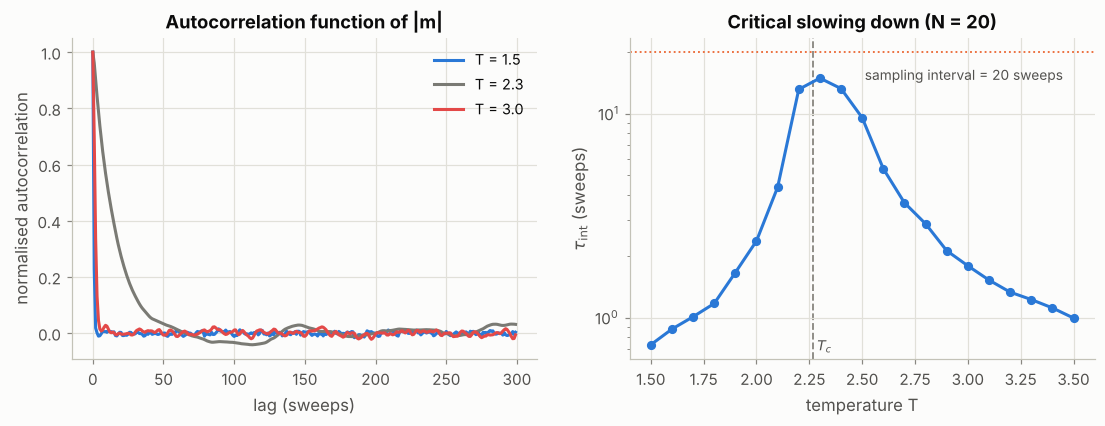

tau_int (sweeps): T=2.0: 2.4  T=2.1: 4.4  T=2.2: 13.1  T=2.3: 14.9  T=2.4: 13.3  T=2.5: 9.5  T=2.6: 5.4


In [4]:
rng = np.random.default_rng(11)
T_ac = np.round(np.arange(1.5, 3.51, 0.1), 2)
N_ac, n_eq, n_run = 20, 2000, 30000
beta = (1 / T_ac).reshape(-1, 1, 1, 1)
s = np.ones((len(T_ac), 1, N_ac, N_ac), dtype=np.int8)
masks = checkerboard_masks(N_ac)
for _ in range(n_eq): metropolis_sweep(s, beta, masks, rng)
mser = np.empty((n_run, len(T_ac)))
for t in range(n_run):
    metropolis_sweep(s, beta, masks, rng)
    mser[t] = np.abs(s.mean(axis=(1, 2, 3)))
taus = np.array([tau_int(mser[:, k])[0] for k in range(len(T_ac))])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
for T_show, c in zip([1.5, 2.3, 3.0], [BLUE, "#7a7a74", RED]):
    k = np.argmin(np.abs(T_ac - T_show)); acf = tau_int(mser[:, k])[1]
    ax.plot(acf[:300], color=c, label=f"T = {T_ac[k]}")
ax.set(title="Autocorrelation function of |m|", xlabel="lag (sweeps)", ylabel="normalised autocorrelation")
ax.legend()
ax = axes[1]
ax.semilogy(T_ac, taus, "o-", color=BLUE)
ax.axhline(20, color=ORANGE, lw=1.2, ls=":"); ax.text(3.45, 17, "sampling interval = 20 sweeps", color=INK2, ha="right", va="top", fontsize=9)
tc_line(ax)
ax.set(title="Critical slowing down (N = 20)", xlabel="temperature T", ylabel=r"$\tau_{\mathrm{int}}$ (sweeps)")
save(fig, "02_autocorrelation"); plt.show()
print("tau_int (sweeps):", "  ".join(f"T={T:.1f}: {t:.1f}" for T, t in zip(T_ac, taus) if 2.0 <= T <= 2.6))

**What to notice.** $\tau_{\text{int}}$ peaks sharply at $T_c$: near the transition, large correlated clusters can only be reorganised by many single-spin flips. Away from $T_c$, $\tau_{\text{int}}$ is one or two sweeps, so samples taken every 20 sweeps are independent. Close to $T_c$ it rises to about 15 sweeps, comparable to the sampling interval, so neighbouring samples there are mildly correlated; the 20 independent chains per temperature compensate. For larger lattices $\tau_{\text{int}}$ at $T_c$ grows roughly as $N^{2.17}$, which is why critical-point simulations get expensive. (Cluster algorithms such as Wolff remove most of this slowing down; we keep Metropolis because the project asks for it.)

### 2.8 Production run
Parameters: temperatures $T = 1.00, 1.05, \dots, 3.50$ (51 values, finer than the suggested 0.2 step so that the critical region is well resolved); 20 chains × 50 samples = **1000 configurations per temperature**; 3000 burn-in sweeps; one sample every 20 sweeps. We generate $N=20$ for the main analysis and $N=10, 30, 40$ for the finite-size study in §8.

In [5]:
TEMPS = np.round(np.arange(1.0, 3.5001, 0.05), 3)
SIZES = [10, 20, 30, 40]
DATA = {}
for N in SIZES:
    path = f"data/ising_N{N}.npz"
    if os.path.exists(path):
        DATA[N] = np.load(path)["configs"]
        print(f"N={N}: loaded cached data {DATA[N].shape}")
    else:
        t0 = time.time()
        DATA[N] = simulate(N, TEMPS, seed=N)
        np.savez_compressed(path, configs=DATA[N], temps=TEMPS)
        print(f"N={N}: simulated {DATA[N].shape} in {time.time() - t0:.0f} s")

N = 20                      # main system size for sections 3-7
X_raw = DATA[N]             # shape (n_T, 1000, 400)
nT, M_per_T, D = X_raw.shape
print(f"\nMain data set: {nT} temperatures x {M_per_T} configurations, each a vector of {D} spins")

N=10: loaded cached data (51, 1000, 100)
N=20: loaded cached data (51, 1000, 400)
N=30: loaded cached data (51, 1000, 900)
N=40: loaded cached data (51, 1000, 1600)

Main data set: 51 temperatures x 1000 configurations, each a vector of 400 spins


### 2.9 Validating the simulation against the exact solution
Before analysing anything, we check that the simulation reproduces Onsager's exact energy and magnetisation. A data-science analysis is only as good as its data.

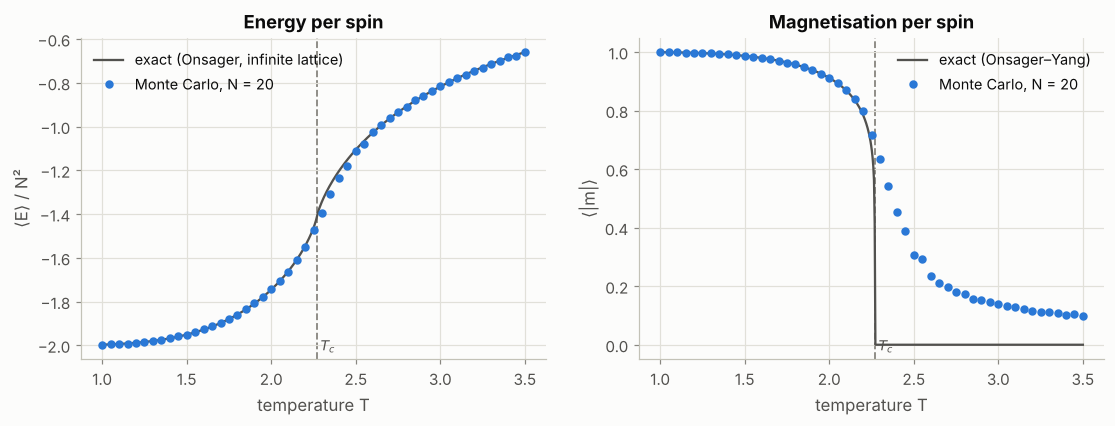

max |E_MC - E_exact| away from Tc (|T-Tc|>0.3): 0.0041


In [6]:
m_all = X_raw.mean(axis=-1)                         # magnetisation of every configuration, (n_T, M)
e_all = energy_per_spin(X_raw, N)
Tfine = np.linspace(1.0, 3.5, 600)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
ax.plot(Tfine, onsager_energy(Tfine), color=INK2, lw=1.5, label="exact (Onsager, infinite lattice)")
ax.plot(TEMPS, e_all.mean(1), "o", color=BLUE, ms=4.5, label="Monte Carlo, N = 20")
tc_line(ax); ax.set(title="Energy per spin", xlabel="temperature T", ylabel="⟨E⟩ / N²"); ax.legend()
ax = axes[1]
ax.plot(Tfine, onsager_m(Tfine), color=INK2, lw=1.5, label="exact (Onsager–Yang)")
ax.plot(TEMPS, np.abs(m_all).mean(1), "o", color=BLUE, ms=4.5, label="Monte Carlo, N = 20")
tc_line(ax); ax.set(title="Magnetisation per spin", xlabel="temperature T", ylabel="⟨|m|⟩"); ax.legend()
save(fig, "03_validation"); plt.show()
err = np.abs(e_all.mean(1) - onsager_energy(TEMPS))
print(f"max |E_MC - E_exact| away from Tc (|T-Tc|>0.3): {err[np.abs(TEMPS - TC) > 0.3].max():.4f}")

**What to notice.** Away from $T_c$ the agreement is excellent. Near $T_c$ and above it, $\langle|m|\rangle$ of the finite lattice stays above zero: with only 400 spins, random fluctuations alone give $|m|\sim 1/N$. That smooth tail is a finite-size effect, not an error.

## 3. How the structure of the configurations changes (Question 1)

### 3.1 Snapshots

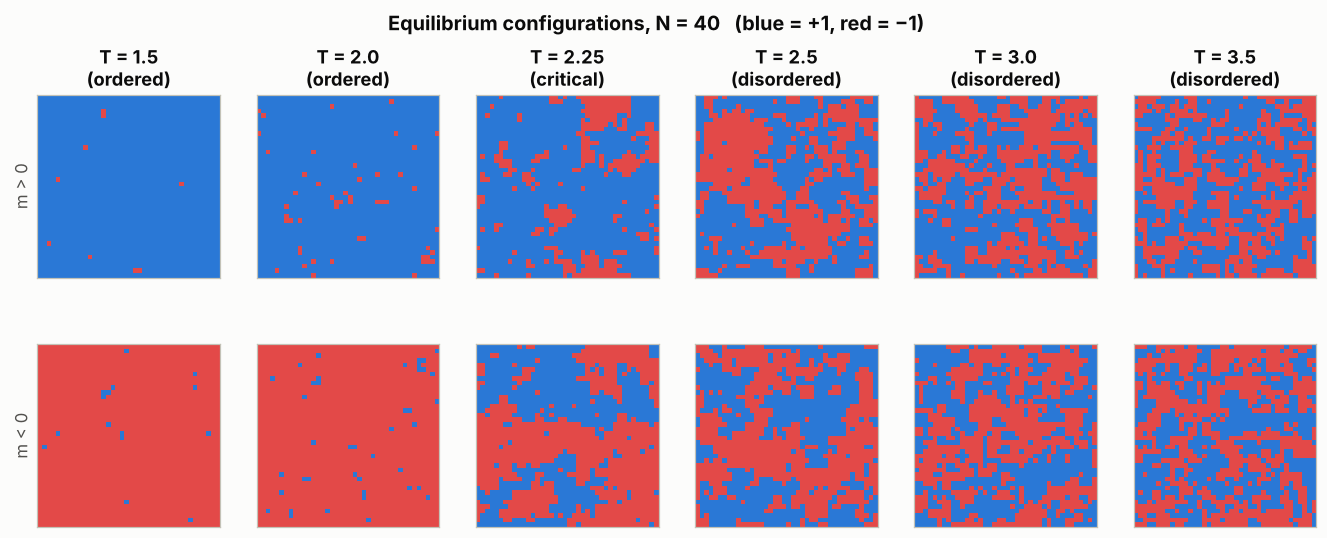

In [7]:
X40 = DATA[40]
T_snap = [1.5, 2.0, 2.25, 2.5, 3.0, 3.5]
fig, axes = plt.subplots(2, 6, figsize=(15, 5.4))
for c, T in enumerate(T_snap):
    k = np.argmin(np.abs(TEMPS - T))
    mk = X40[k].mean(1)
    picks = [np.flatnonzero(mk >= 0)[0], np.flatnonzero(mk < 0)[0]]    # one m>0 and one m<0 configuration
    for r in range(2):
        cfg = X40[k, picks[r]].reshape(40, 40)
        ax = axes[r, c]; ax.imshow(cfg, cmap=SPIN_CMAP, vmin=-1, vmax=1); ax.set(xticks=[], yticks=[]); ax.grid(False)
        for sp in ax.spines.values(): sp.set_visible(True); sp.set_color(AXIS)
    phase = "ordered" if T < TC - 0.1 else ("critical" if abs(T - TC) <= 0.1 else "disordered")
    axes[0, c].set_title(f"T = {TEMPS[k]}\n({phase})")
axes[0, 0].set_ylabel("m > 0", fontsize=11, color=INK2); axes[1, 0].set_ylabel("m < 0", fontsize=11, color=INK2)
fig.suptitle("Equilibrium configurations, N = 40   (blue = +1, red = −1)", fontsize=13, fontweight="bold", y=1.0)
save(fig, "04_snapshots"); plt.show()

**What to notice.** Below $T_c$ the lattice is almost uniformly one colour with a few isolated minority spins; the top row shows configurations with $m>0$ and the bottom row with $m<0$, confirming that both ordered states are present in the data. Near $T_c$ there are clusters of **every size**, from single spins to lattice-spanning domains — the visual signature of a diverging correlation length. Above $T_c$ the pattern is fine-grained noise with small clusters.

### 3.2 Spin–spin correlation function
To quantify cluster size we compute $G(r)=\langle s_{\mathbf x}\,s_{\mathbf x+r\hat e}\rangle$, averaged over all sites, both lattice directions and all configurations.

- Ordered phase: $G(r)\to m_0^2$, a plateau (long-range order).
- At $T_c$: power-law decay $G(r)\sim r^{-1/4}$ (the exponent $\eta=1/4$ is exact in 2D).
- Disordered phase: exponential decay $G(r)\sim e^{-r/\xi}$.

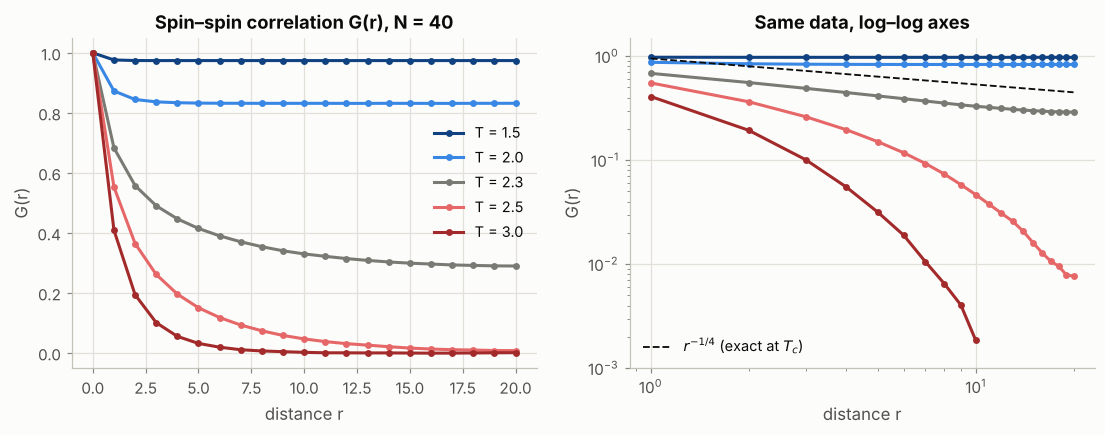

In [8]:
def correlation_function(configs, N):
    s = configs.reshape(-1, N, N).astype(np.float32)
    return np.array([0.5 * (np.mean(s * np.roll(s, r, -1)) + np.mean(s * np.roll(s, r, -2))) for r in range(N // 2 + 1)])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
r = np.arange(21)
for T, col in zip([1.5, 2.0, 2.3, 2.5, 3.0], ["#104281", "#3987e5", "#7a7a74", "#e66767", "#a32a2a"]):
    k = np.argmin(np.abs(TEMPS - T)); G = correlation_function(X40[k], 40)
    axes[0].plot(r, G, "o-", ms=3.5, color=col, label=f"T = {TEMPS[k]}")
    pos = G[1:] > 1e-3                                   # log axes: show only clearly positive values
    axes[1].loglog(r[1:][pos], G[1:][pos], "o-", ms=3.5, color=col)
axes[1].loglog(r[1:], 0.95 * r[1:] ** -0.25, color=INK, lw=1.2, ls="--", label=r"$r^{-1/4}$ (exact at $T_c$)")
axes[0].set(title="Spin–spin correlation G(r), N = 40", xlabel="distance r", ylabel="G(r)")
axes[0].legend(loc="upper right", bbox_to_anchor=(1.0, 0.78))
axes[1].set(title="Same data, log–log axes", xlabel="distance r", ylabel="G(r)", ylim=(1e-3, 1.5)); axes[1].legend(loc="lower left")
save(fig, "05_correlation_function"); plt.show()

**What to notice.** The curves split into three families exactly as predicted: plateaus below $T_c$, a slow, nearly straight-line decay on the log–log plot close to $T_c$ (roughly parallel to $r^{-1/4}$; the finite lattice and the fact that $T=2.3$ is slightly above $T_c$ cause small deviations), and rapid, exponential decay above $T_c$. **This change of correlations is precisely what PCA will detect**, because PCA works entirely with the covariance matrix $\langle s_i s_j\rangle - \langle s_i\rangle\langle s_j\rangle$, which is the correlation function in matrix form.

## 4. Principal Component Analysis: the theory

### 4.1 The data matrix
Flatten each configuration into a vector $\mathbf s^{(n)}\in\{-1,+1\}^{D}$ with $D=N^2$ and stack all $M$ configurations as rows:

$$X=\begin{pmatrix}\mathbf s^{(1)}\\ \vdots\\ \mathbf s^{(M)}\end{pmatrix}\in\mathbb R^{M\times D}.$$

Here $M = 51\times1000 = 51\,000$ and $D=400$. **Centring** subtracts each column mean: $X_{n\alpha}\to X_{n\alpha}-\langle X_\alpha\rangle$.

### 4.2 The covariance matrix
$$C=\frac{1}{M-1}X^{\mathsf T}X\in\mathbb R^{D\times D},\qquad C_{\alpha\beta}=\operatorname{Cov}(s_\alpha,s_\beta).$$
Diagonal entries are the variances of individual spins; off-diagonal entries say how strongly two spins move together.

### 4.3 PCA as variance maximisation
Find the unit vector $\mathbf v$ along which the projected data $z=\mathbf s\cdot\mathbf v$ has the largest variance. The variance of $z$ is $\mathbf v^{\mathsf T}C\mathbf v$, so we maximise it subject to $\mathbf v^{\mathsf T}\mathbf v=1$. With a Lagrange multiplier $\lambda$:

$$\frac{\partial}{\partial\mathbf v}\left[\mathbf v^{\mathsf T}C\mathbf v-\lambda(\mathbf v^{\mathsf T}\mathbf v-1)\right]=0\;\Longrightarrow\;C\mathbf v=\lambda\mathbf v.$$

So the best direction is an **eigenvector** of $C$, and the variance along it is its **eigenvalue** $\lambda$. The largest eigenvalue $\lambda_1$ gives the first principal component $\mathbf v_1$; the next, orthogonal to it, gives $\mathbf v_2$; and so on. Because $C$ is symmetric, the eigenvectors are orthogonal and the eigenvalues are real and non-negative.

### 4.4 Explained variance ratio
The total variance is $\operatorname{tr}C=\sum_j\lambda_j$. The fraction carried by component $k$ is

$$f_k=\frac{\lambda_k}{\sum_j\lambda_j}.$$

A large $f_1$ means the data are essentially one-dimensional: a single collective coordinate describes most of the variation.

### 4.5 Computing it: the SVD
Rather than forming $C$, we take the singular value decomposition $X=U\Sigma V^{\mathsf T}$. Then $C=V\,\frac{\Sigma^2}{M-1}\,V^{\mathsf T}$, so the rows of $V^{\mathsf T}$ are the principal directions and $\lambda_k=\sigma_k^2/(M-1)$. This is numerically more stable, and it is what `sklearn.decomposition.PCA` does internally.

### 4.6 Projections
The coordinates of configuration $n$ in PCA space are $z_k^{(n)}=\mathbf s^{(n)}\cdot\mathbf v_k$. Keeping only $z_1,z_2$ compresses 400 numbers into 2. Centring is needed to *find* the directions $\mathbf v_k$; for the projections we follow the project's definition and use the raw spins. The difference is only a constant shift $\boldsymbol\mu\cdot\mathbf v_k$, but leaving it out keeps the $+m$ and $-m$ states exactly symmetric about $z_1=0$, even though our 20 chains per temperature do not split exactly 10/10 between the two signs.

### 4.7 A physics shortcut worth knowing
With periodic boundaries the system is **translation invariant**: $C_{\alpha\beta}$ depends only on the displacement between sites $\alpha$ and $\beta$. Such a matrix is diagonalised by **Fourier modes** $e^{i\mathbf k\cdot\mathbf x}$, and its eigenvalues are the **structure factor** $S(\mathbf k)$. So the principal components of Ising data must be plane waves:

- $\mathbf k=0$: the uniform vector $v_\alpha=1/N$, for which $z=\frac1N\sum s = N\,m$ — the **magnetisation**;
- the smallest non-zero wavevectors $(2\pi/N,0)$ and $(0,2\pi/N)$, each with a cosine and a sine: **four degenerate** modes.

We will now check whether PCA, which knows nothing of this, finds exactly that.

In [9]:
def pca(X):
    '''PCA from scratch via SVD. Returns eigenvalues, principal directions (rows), mean.'''
    mu = X.mean(axis=0)
    Xc = X - mu
    _, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    lam = S**2 / (len(X) - 1)
    signs = np.sign(Vt.sum(axis=1)); signs[signs == 0] = 1
    return lam, Vt * signs[:, None], mu       # sign convention: sum(v_k) > 0, so z1 = +N m

X = X_raw.reshape(-1, D).astype(np.float32)   # (51000, 400) data matrix
T_of_row = np.repeat(TEMPS, M_per_T)          # temperature label of each row (used only for colouring)

t0 = time.time()
lam, V, mu = pca(X)
f = lam / lam.sum()
Z = X @ V[:6].T          # projections z_k = s . v_k, as defined in the project (centring is used to FIND v_k)
print(f"PCA of a {X.shape} matrix took {time.time() - t0:.1f} s")

sk = SkPCA(n_components=10).fit(X)            # cross-check against scikit-learn
print("matches scikit-learn:", np.allclose(sk.explained_variance_ratio_, f[:10], atol=1e-5))
print("f_1..f_6 =", np.round(f[:6], 4))

PCA of a (51000, 400) matrix took 3.0 s
matches scikit-learn: True
f_1..f_6 = [0.5025 0.012  0.0119 0.0118 0.0117 0.0082]


## 5. The principal components of Ising data (Questions 2 and 3)

### 5.1 How much variance does each component explain?

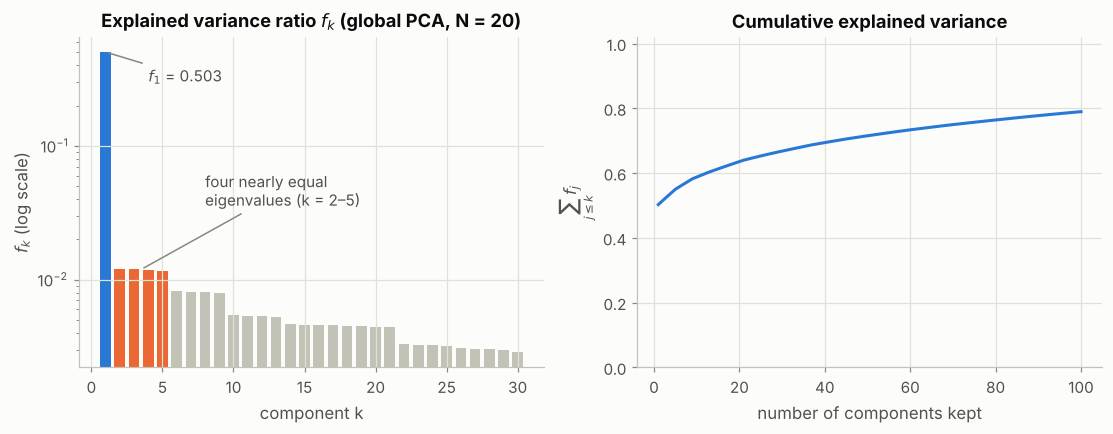

first component: 50.3%  |  components 2-5: 4.7% together  |  first 10: 58.8%


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
k = np.arange(1, 31)
ax = axes[0]
bar_col = [BLUE] + [ORANGE] * 4 + [AXIS] * 25
ax.bar(k, f[:30], color=bar_col, width=0.75)
ax.set_yscale("log"); ax.set(title="Explained variance ratio $f_k$ (global PCA, N = 20)", xlabel="component k", ylabel="$f_k$ (log scale)")
ax.annotate(f"$f_1$ = {f[0]:.3f}", (1, f[0]), (4, f[0] * 0.6), color=INK2, fontsize=10, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.annotate("four nearly equal\neigenvalues (k = 2–5)", (3.5, f[2]), (8, f[2] * 3), color=INK2, fontsize=10, arrowprops=dict(arrowstyle="-", color=MUTED))
ax = axes[1]
ax.plot(np.arange(1, 101), np.cumsum(f[:100]), color=BLUE)
ax.set(title="Cumulative explained variance", xlabel="number of components kept", ylabel=r"$\sum_{j\leq k} f_j$", ylim=(0, 1.02))
save(fig, "06_scree_plot"); plt.show()
print(f"first component: {100*f[0]:.1f}%  |  components 2-5: {100*f[1:5].sum():.1f}% together  |  first 10: {100*f[:10].sum():.1f}%")

**What to notice.** One component carries about half of all the variance of the 51 000 configurations, and it is followed by a near-degenerate group of four. The remaining ~395 components share the rest in small, slowly decreasing amounts. This is exactly the pattern predicted in §4.7: one $\mathbf k=0$ mode, then four smallest-$|\mathbf k|$ modes.

### 5.2 What do the principal directions look like?
Each $\mathbf v_k$ has 400 entries — one weight per lattice site — so we can reshape it to $20\times20$ and display it.

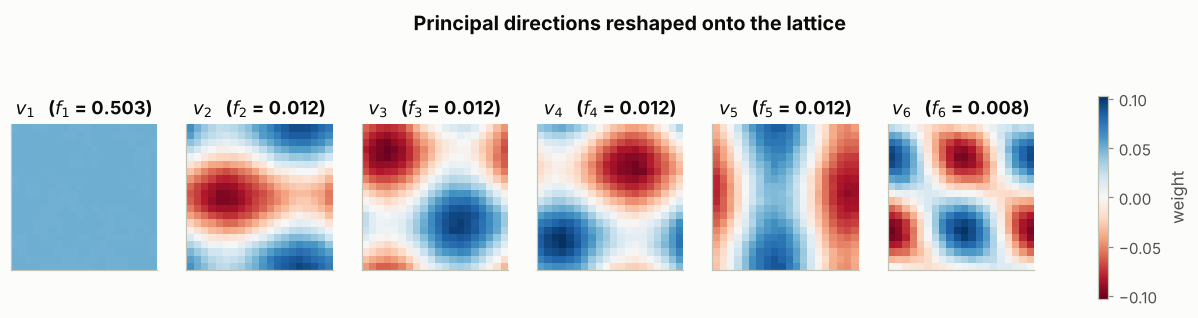

v1: mean weight = 0.05000 (1/N = 0.05000), relative spread = 0.0022


In [11]:
fig, axes = plt.subplots(1, 6, figsize=(15, 3.0))
vmax = np.abs(V[:6]).max()
for i, ax in enumerate(axes):
    im = ax.imshow(V[i].reshape(N, N), cmap="RdBu", vmin=-vmax, vmax=vmax)
    ax.set(title=f"$v_{i+1}$   ($f_{i+1}$ = {f[i]:.3f})", xticks=[], yticks=[]); ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.8, label="weight")
fig.suptitle("Principal directions reshaped onto the lattice", fontsize=13, fontweight="bold", y=1.06)
save(fig, "07_principal_directions"); plt.show()
print(f"v1: mean weight = {V[0].mean():.5f} (1/N = {1/N:.5f}), relative spread = {V[0].std()/V[0].mean():.4f}")

**What to notice.** $\mathbf v_1$ is **uniform**: every site has weight $\approx 1/N = 0.05$. Hence

$$z_1=\mathbf s\cdot\mathbf v_1=\frac1N\sum_{ij}s_{ij}=N\,m .$$

PCA has rediscovered the **order parameter** from raw data, without being told what a magnetisation is. Components 2–5 are long-wavelength waves (one period across the lattice). Because they are degenerate, any rotation within that four-dimensional subspace is equally valid, so the exact pattern of an individual $\mathbf v_2$ is arbitrary; the subspace is what is meaningful. Component 6 starts the next shell of wavevectors.

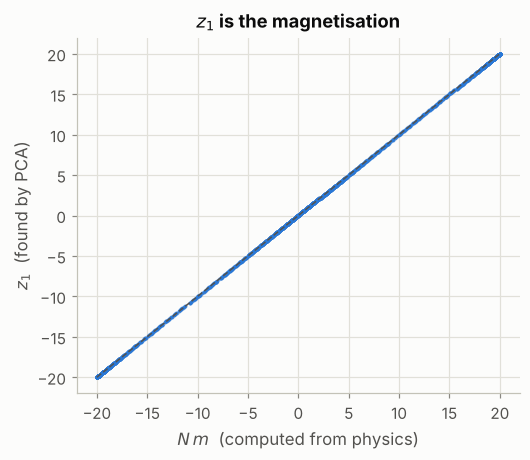

correlation coefficient: 0.99999999


In [12]:
fig, ax = plt.subplots(figsize=(5.2, 4.2))
idx = np.random.default_rng(0).choice(len(X), 4000, replace=False)
ax.plot(N * m_all.ravel()[idx], Z[idx, 0], ".", ms=3, color=BLUE, alpha=0.5)
ax.plot([-N, N], [-N, N], color=INK2, lw=1, ls="--")
ax.set(title="$z_1$ is the magnetisation", xlabel=r"$N\,m$  (computed from physics)", ylabel=r"$z_1$  (found by PCA)")
save(fig, "08_z1_vs_magnetisation"); plt.show()
print("correlation coefficient:", np.corrcoef(N * m_all.ravel(), Z[:, 0])[0, 1].round(8))

## 6. PCA across the phase transition (Questions 3 and 4)

### 6.1 The PCA map of all 51 000 configurations
Below, every configuration is one dot at $(z_1,z_2)$, coloured by the temperature at which it was generated. **PCA never saw these colours**; they are added afterwards only to interpret the map.

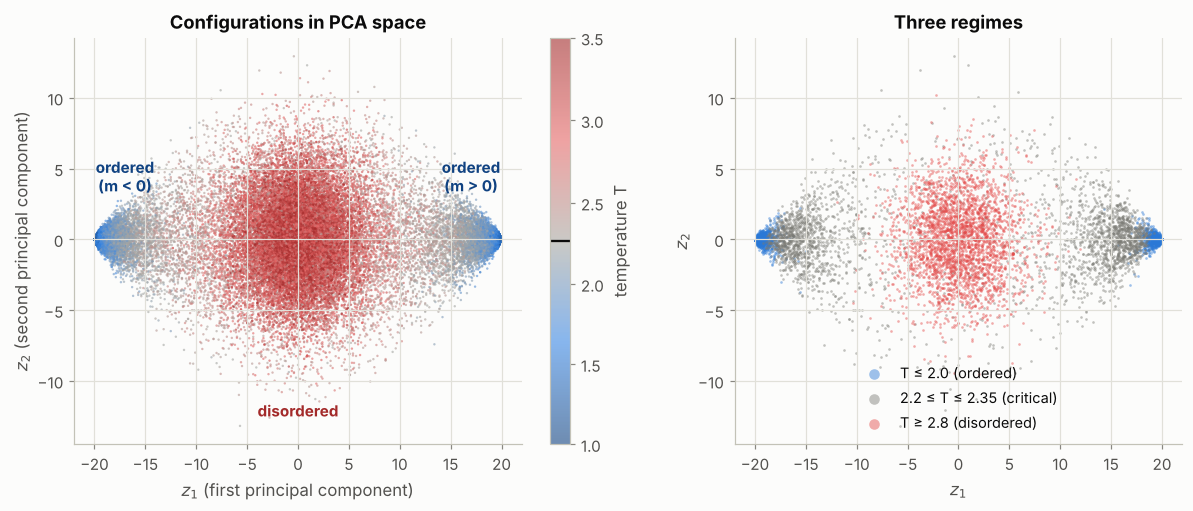

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
order = np.random.default_rng(1).permutation(len(X))
sc = ax.scatter(Z[order, 0], Z[order, 1], c=T_of_row[order], cmap=TEMP_CMAP, norm=TEMP_NORM, s=2.5, alpha=0.6, linewidths=0)
cb = fig.colorbar(sc, ax=ax, label="temperature T"); cb.ax.axhline(TC, color=INK, lw=1.5)
ax.set(title="Configurations in PCA space", xlabel=r"$z_1$ (first principal component)", ylabel=r"$z_2$ (second principal component)")
ax.text(-17, 3.4, "ordered\n(m < 0)", color="#104281", ha="center", fontsize=10, fontweight="bold")
ax.text(17, 3.4, "ordered\n(m > 0)", color="#104281", ha="center", fontsize=10, fontweight="bold")
ax.text(0, -12.5, "disordered", color="#a32a2a", ha="center", fontsize=10, fontweight="bold")

ax = axes[1]
groups = [("T ≤ 2.0 (ordered)", T_of_row <= 2.0, BLUE), ("2.2 ≤ T ≤ 2.35 (critical)", (T_of_row >= 2.2) & (T_of_row <= 2.35), "#7a7a74"), ("T ≥ 2.8 (disordered)", T_of_row >= 2.8, RED)]
for lab, sel, col in groups:
    ii = np.flatnonzero(sel); ii = np.random.default_rng(2).choice(ii, min(3000, len(ii)), replace=False)
    ax.scatter(Z[ii, 0], Z[ii, 1], s=3, color=col, alpha=0.45, linewidths=0, label=lab)
ax.set(title="Three regimes", xlabel=r"$z_1$", ylabel=r"$z_2$"); ax.legend(markerscale=4, loc="lower center")
save(fig, "09_pca_scatter"); plt.show()

**What to notice.** The map has three regions. Ordered configurations form **two tight clusters** at $z_1\approx\pm N=\pm20$ (the $+$ and $-$ states). Disordered configurations form **one compact blob** at the origin. Critical configurations **stretch along a bridge** between them. The spread in $z_2$ is smallest in the ordered phase and largest just above $T_c$ (around $T\approx2.4$–$2.6$): the long-wavelength fluctuations captured by components 2–5 are strongest where large clusters of both signs coexist. So yes — the first two components separate ordered from disordered configurations, and $z_1$ alone does most of the work.

### 6.2 $f_1(T)$ and $f_2(T)$: PCA at each temperature
§5 analysed all temperatures together. To follow how the structure changes with $T$ we now perform PCA **separately on the 1000 configurations at each temperature**, giving $f_1(T)$ and $f_2(T)$.

**A short derivation.** If $\mathbf v_1$ is uniform, then $\lambda_1=\operatorname{Var}(z_1)=N^2\operatorname{Var}(m)$. The total variance is $\sum_j\lambda_j=\sum_\alpha\operatorname{Var}(s_\alpha)\approx N^2$, since each spin has variance $\approx1$ when $\langle s_\alpha\rangle\approx0$. Hence

$$f_1(T)\approx\langle m^2\rangle-\langle m\rangle^2\approx\langle m^2\rangle .$$

So $f_1$ should behave like an order parameter: close to 1 deep in the ordered phase and close to $1/N^2$ in the disordered phase.

**The symmetry experiment.** As a control we also compute $f_1$ using only the configurations with $m>0$, i.e. data from **one** ordered state, as a single long Metropolis chain would produce.

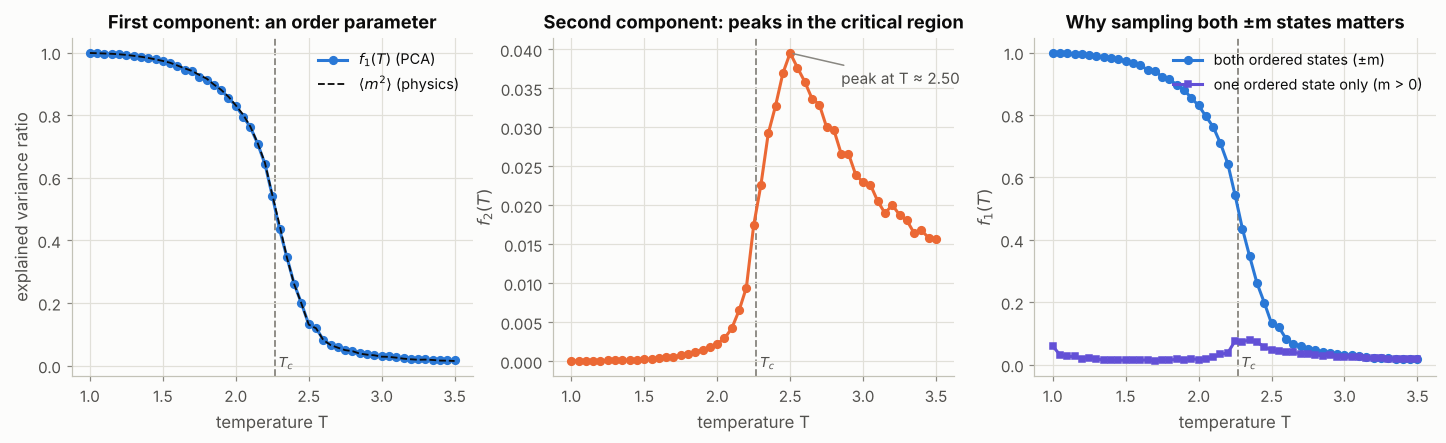

In [14]:
f1_T, f2_T, f1_onesided, lam1_T = (np.empty(nT) for _ in range(4))
for i in range(nT):
    lam_i, _, _ = pca(X_raw[i].astype(np.float32))
    f1_T[i], f2_T[i], lam1_T[i] = lam_i[0] / lam_i.sum(), lam_i[1] / lam_i.sum(), lam_i[0]
    pos = X_raw[i][m_all[i] > 0].astype(np.float32)
    lp, _, _ = pca(pos); f1_onesided[i] = lp[0] / lp.sum()
m2 = (m_all**2).mean(1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.0))
ax = axes[0]
ax.plot(TEMPS, f1_T, "o-", color=BLUE, label="$f_1(T)$ (PCA)")
ax.plot(TEMPS, m2, color=INK, lw=1.2, ls="--", label=r"$\langle m^2\rangle$ (physics)")
tc_line(ax); ax.set(title="First component: an order parameter", xlabel="temperature T", ylabel="explained variance ratio"); ax.legend()
ax = axes[1]
ax.plot(TEMPS, f2_T, "o-", color=ORANGE)
tc_line(ax); ax.set(title="Second component: peaks in the critical region", xlabel="temperature T", ylabel="$f_2(T)$")
Tpk = TEMPS[np.argmax(f2_T)]; ax.annotate(f"peak at T ≈ {Tpk:.2f}", (Tpk, f2_T.max()), (Tpk + 0.35, f2_T.max() * 0.9), color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED))
ax = axes[2]
ax.plot(TEMPS, f1_T, "o-", color=BLUE, label="both ordered states (±m)")
ax.plot(TEMPS, f1_onesided, "s-", color=VIOLET, ms=4, label="one ordered state only (m > 0)")
tc_line(ax); ax.set(title="Why sampling both ±m states matters", xlabel="temperature T", ylabel="$f_1(T)$"); ax.legend(loc="upper right")
save(fig, "10_f1_f2_vs_T"); plt.show()

**What to notice.**

- **Left.** $f_1(T)$ sits on top of $\langle m^2\rangle$, confirming the derivation. It falls from $\approx1$ to $\approx0.02$, with the steepest drop around $T_c$. A purely statistical quantity — what fraction of the variance one direction carries — behaves as an order parameter.
- **Middle.** $f_2$ is small in both phases and **peaks just above $T_c$**. In the ordered phase nearly everything is in $z_1$; in the disordered phase variance is spread evenly over all 400 directions; near $T_c$ the long-wavelength fluctuations (large clusters) become important, so the second component gains weight. Its peak sits slightly above $T_c$ for a finite lattice, much like the susceptibility peak (§7).
- **Right.** With only one ordered state, $f_1$ collapses at low $T$: the configurations are all nearly identical, the only variance left is a few random spin flips, and no single direction dominates. **PCA detects the transition through the variance between the two symmetry-broken states.** Sampling must respect the $\mathbb Z_2$ symmetry of $H$, which is why §2.5 matters.

### 6.3 The distribution $P(z_1)$ below, near and above $T_c$

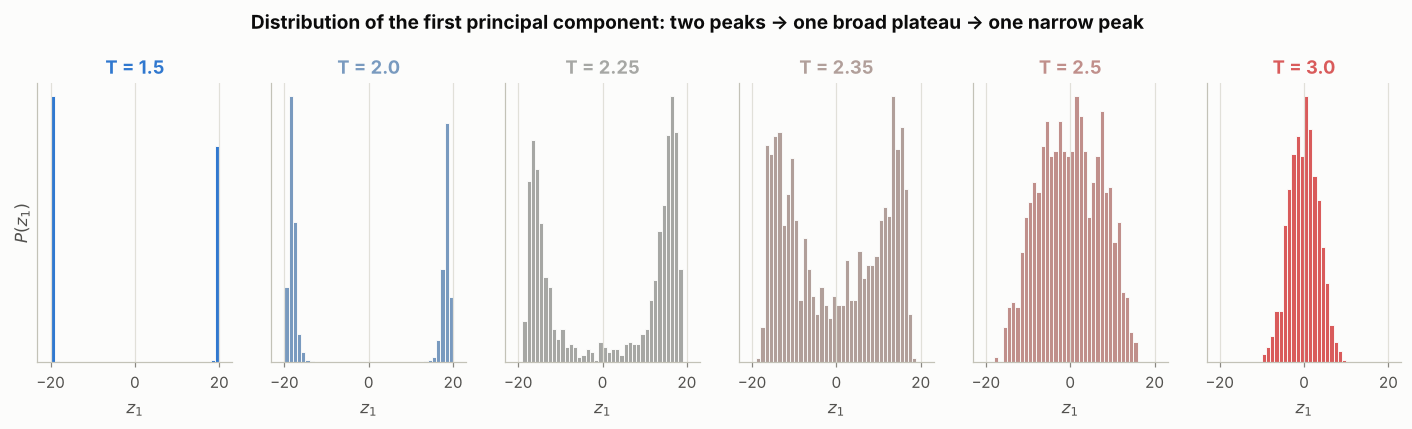

In [15]:
T_hist = [1.5, 2.0, 2.25, 2.35, 2.5, 3.0]
z1_T = Z[:, 0].reshape(nT, M_per_T)
fig, axes = plt.subplots(1, len(T_hist), figsize=(16, 3.3), sharex=True)
bins = np.linspace(-21, 21, 43)
for ax, T in zip(axes, T_hist):
    k = np.argmin(np.abs(TEMPS - T))
    ax.hist(z1_T[k], bins=bins, density=True, color=TEMP_CMAP(TEMP_NORM(TEMPS[k])), edgecolor=SURFACE, linewidth=0.6)
    ax.set_title(f"T = {TEMPS[k]}", color=TEMP_CMAP(TEMP_NORM(TEMPS[k]))); ax.set_xlabel("$z_1$"); ax.set_yticks([])
axes[0].set_ylabel("$P(z_1)$")
fig.suptitle("Distribution of the first principal component: two peaks → one broad plateau → one narrow peak", fontsize=12.5, fontweight="bold", y=1.08)
save(fig, "11_P_z1_histograms"); plt.show()

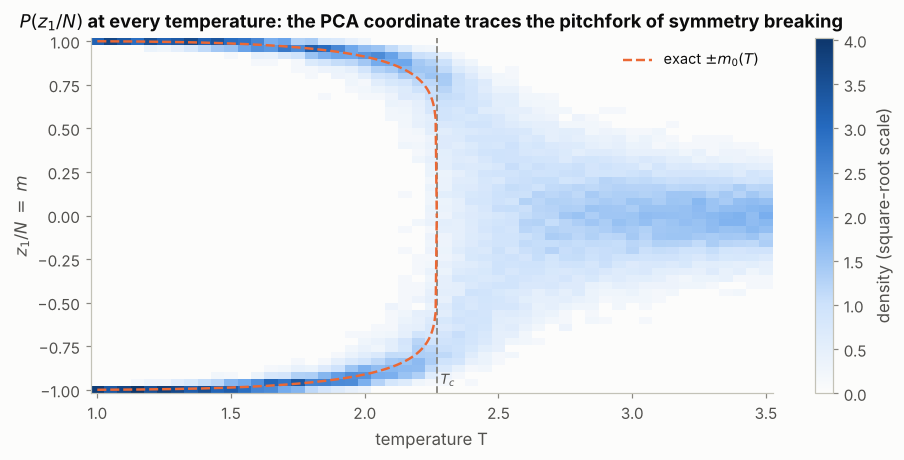

In [16]:
# The same information for all 51 temperatures at once: a "phase diagram" drawn by PCA
edges = np.linspace(-1.02, 1.02, 52)                 # bin centres fall on -1.00, -0.96, ..., 1.00
H = np.array([np.histogram(z1_T[i] / N, bins=edges, density=True)[0] for i in range(nT)])
fig, ax = plt.subplots(figsize=(10, 4.2))
seq = LinearSegmentedColormap.from_list("seq", [SURFACE, "#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
im = ax.imshow(np.sqrt(H.T), origin="lower", aspect="auto", cmap=seq, extent=[TEMPS[0] - 0.025, TEMPS[-1] + 0.025, edges[0], edges[-1]])
Tf = np.linspace(1.0, TC, 300)
ax.plot(Tf, onsager_m(Tf), color=ORANGE, lw=1.6, ls="--", label=r"exact $\pm m_0(T)$"); ax.plot(Tf, -onsager_m(Tf), color=ORANGE, lw=1.6, ls="--")
tc_line(ax); ax.grid(False)
ax.set(title=r"$P(z_1/N)$ at every temperature: the PCA coordinate traces the pitchfork of symmetry breaking", xlabel="temperature T", ylabel=r"$z_1 / N \;=\; m$")
fig.colorbar(im, ax=ax, label="density (square-root scale)"); ax.legend(loc="upper right")
save(fig, "12_P_z1_heatmap"); plt.show()

**What to notice.**

- **Below $T_c$:** $P(z_1)$ is **bimodal**, with sharp peaks at $\pm N m_0(T)$. Configurations occupy two separated regions of PCA space.
- **Near $T_c$:** the peaks move inwards, broaden and merge into a wide, flat distribution. Every value of the magnetisation between the two states is roughly equally likely — large fluctuations again.
- **Above $T_c$:** a single narrow, approximately Gaussian peak at $z_1=0$ whose width shrinks as $T$ increases (by the central limit theorem, a sum of weakly correlated spins).

The heat map shows that the peaks of $P(z_1/N)$ follow the exact Onsager curve $\pm m_0(T)$ and merge at $T_c$: the classic **pitchfork bifurcation** of spontaneous symmetry breaking, drawn here purely from a data-driven coordinate.

## 7. Comparison with conventional observables (Question 5)

### 7.1 Definitions
- $\langle m\rangle$: average magnetisation. In a finite system sampled correctly (both $\pm m$ states equally), $\langle m\rangle=0$ at **every** temperature by symmetry, so it is not a useful order parameter. (In our data it scatters by about $\pm0.2$ below $T_c$, simply because 20 chains rarely split exactly 10/10 between the two signs; the scatter is of order $1/\sqrt{20}$.)
- $\langle|m|\rangle$: the standard finite-size order parameter.
- Susceptibility, as defined in the project: $\chi=\dfrac{N^2}{T}\left(\langle m^2\rangle-\langle m\rangle^2\right)$. This is the fluctuation–dissipation relation: the response of $m$ to a field equals its variance.

**A subtlety worth explaining in the viva.** Because $\langle m\rangle\approx0$ in our symmetric data, the formula above gives $\chi\approx N^2\langle m^2\rangle/T$, which *grows* as $T\to0$: it measures the jump between the $+$ and $-$ states, not fluctuations within one phase. The standard finite-size remedy is

$$\chi'=\frac{N^2}{T}\left(\langle m^2\rangle-\langle|m|\rangle^2\right),$$

which equals $\chi$ above $T_c$ and gives the correct within-phase susceptibility below it. We plot both.

- **Binder cumulant** $U_4=1-\dfrac{\langle m^4\rangle}{3\langle m^2\rangle^2}$: tends to $2/3$ in the ordered phase and to $0$ in the disordered phase (Gaussian $m$). Its curves for different $N$ cross near $T_c$, which we use in §8.

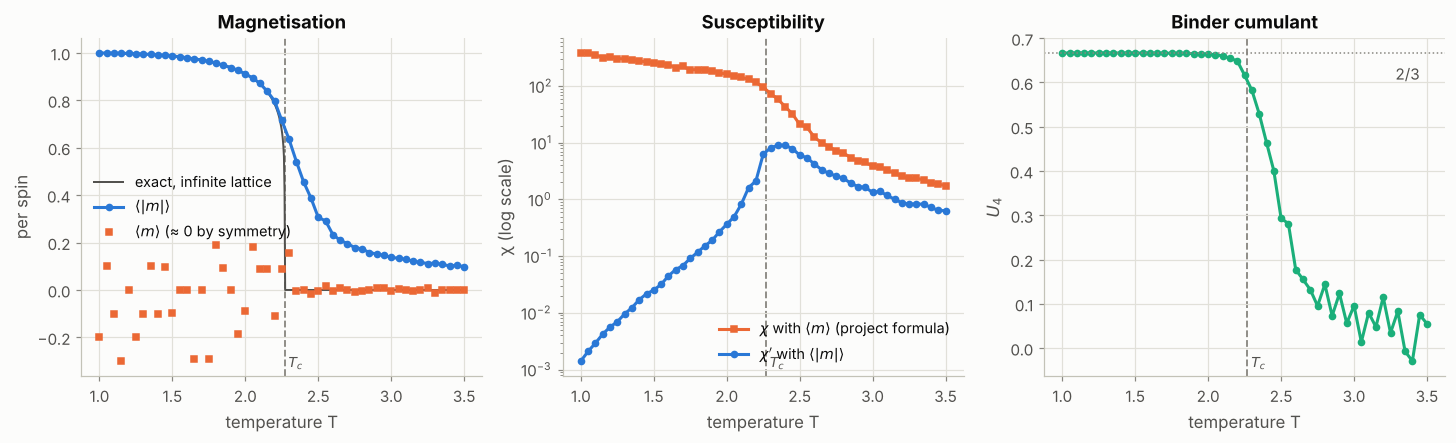

chi' peaks at T = 2.35 for N = 20 (finite-size shifted from Tc = 2.269)


In [17]:
abs_m = np.abs(m_all).mean(1)
mean_m = m_all.mean(1)
chi = N**2 / TEMPS * ((m_all**2).mean(1) - mean_m**2)
chi_p = N**2 / TEMPS * ((m_all**2).mean(1) - abs_m**2)
U4 = 1 - (m_all**4).mean(1) / (3 * (m_all**2).mean(1) ** 2)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.0))
ax = axes[0]
ax.plot(Tfine, onsager_m(Tfine), color=INK2, lw=1.3, label="exact, infinite lattice")
ax.plot(TEMPS, abs_m, "o-", color=BLUE, ms=4, label=r"$\langle|m|\rangle$")
ax.plot(TEMPS, mean_m, "s", color=ORANGE, ms=4, label=r"$\langle m\rangle$ (≈ 0 by symmetry)")
tc_line(ax); ax.set(title="Magnetisation", xlabel="temperature T", ylabel="per spin"); ax.legend()
ax = axes[1]
ax.semilogy(TEMPS, chi, "s-", color=ORANGE, ms=4, label=r"$\chi$ with $\langle m\rangle$ (project formula)")
ax.semilogy(TEMPS, chi_p, "o-", color=BLUE, ms=4, label=r"$\chi'$ with $\langle|m|\rangle$")
tc_line(ax); ax.set(title="Susceptibility", xlabel="temperature T", ylabel="χ (log scale)"); ax.legend()
ax = axes[2]
ax.plot(TEMPS, U4, "o-", color=AQUA, ms=4)
ax.axhline(2 / 3, color=MUTED, lw=1, ls=":"); ax.text(3.45, 0.64, "2/3", color=INK2, ha="right", va="top")
tc_line(ax); ax.set(title="Binder cumulant", xlabel="temperature T", ylabel="$U_4$")
save(fig, "13_conventional_observables"); plt.show()
print(f"chi' peaks at T = {TEMPS[np.argmax(chi_p)]:.2f} for N = {N} (finite-size shifted from Tc = {TC:.3f})")

### 7.2 PCA quantities side by side with physics
Every conventional observable has a PCA counterpart, because $z_1=Nm$:

| Physics | PCA |
|---|---|
| $\langle m^2\rangle$ | $f_1(T)$ |
| $\langle|m|\rangle$ | $\langle|z_1|\rangle/N$ |
| $\chi'$ | $\chi_{\text{PCA}}=\frac{1}{T}\left(\langle z_1^2\rangle-\langle|z_1|\rangle^2\right)$ |
| $U_4$ | $1-\langle z_1^4\rangle/3\langle z_1^2\rangle^2$ |
| peak of $\chi'$ (critical fluctuations) | peak of $f_2(T)$ |

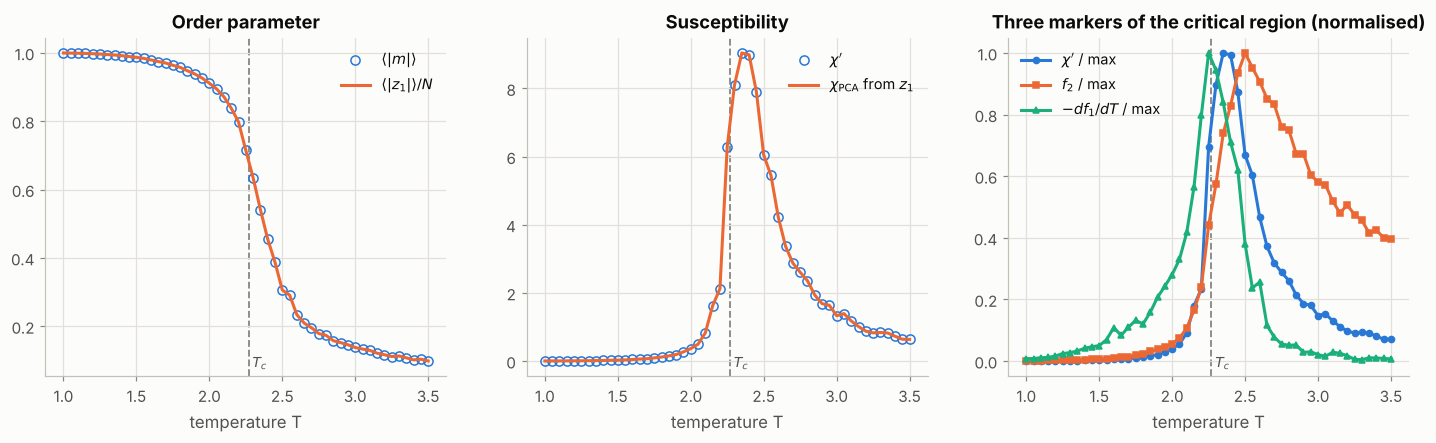

peak positions (N=20):  chi' -> 2.35,  f2 -> 2.50,  -df1/dT -> 2.25   (Tc = 2.269)


In [18]:
z1 = z1_T
abs_z1 = np.abs(z1).mean(1) / N
chi_pca = ((z1**2).mean(1) - np.abs(z1).mean(1) ** 2) / TEMPS
fig, axes = plt.subplots(1, 3, figsize=(16, 4.0))
ax = axes[0]
ax.plot(TEMPS, abs_m, "o", color=BLUE, ms=6, mfc="none", label=r"$\langle|m|\rangle$")
ax.plot(TEMPS, abs_z1, "-", color=ORANGE, label=r"$\langle|z_1|\rangle / N$")
tc_line(ax); ax.set(title="Order parameter", xlabel="temperature T"); ax.legend()
ax = axes[1]
ax.plot(TEMPS, chi_p, "o", color=BLUE, ms=6, mfc="none", label=r"$\chi'$")
ax.plot(TEMPS, chi_pca, "-", color=ORANGE, label=r"$\chi_{\mathrm{PCA}}$ from $z_1$")
tc_line(ax); ax.set(title="Susceptibility", xlabel="temperature T"); ax.legend()
ax = axes[2]
ax.plot(TEMPS, chi_p / chi_p.max(), "o-", color=BLUE, ms=4, label=r"$\chi'$ / max")
ax.plot(TEMPS, f2_T / f2_T.max(), "s-", color=ORANGE, ms=4, label=r"$f_2$ / max")
ax.plot(TEMPS, -np.gradient(f1_T, TEMPS) / (-np.gradient(f1_T, TEMPS)).max(), "^-", color=AQUA, ms=4, label=r"$-df_1/dT$ / max")
tc_line(ax); ax.set(title="Three markers of the critical region (normalised)", xlabel="temperature T"); ax.legend()
save(fig, "14_pca_vs_physics"); plt.show()
print("peak positions (N=20):  chi' -> %.2f,  f2 -> %.2f,  -df1/dT -> %.2f   (Tc = %.3f)"
      % (TEMPS[np.argmax(chi_p)], TEMPS[np.argmax(f2_T)], TEMPS[np.argmax(-np.gradient(f1_T, TEMPS))], TC))

**What to notice.** The PCA order parameter and susceptibility are **identical** to the physics ones (they are mathematically the same quantity once $\mathbf v_1$ is uniform). The genuinely new PCA signatures peak in the same critical window as $\chi'$. The steepest descent of $f_1(T)$ lands almost exactly on $T_c$ even for $N=20$, while $f_2(T)$ peaks somewhat higher, where long-wavelength fluctuations are largest in a finite lattice.

## 8. Finite-size analysis: estimating $T_c$ from PCA alone (Question 6)

A single lattice size gives rounded features at slightly shifted temperatures. **Finite-size scaling** says that as $N$ grows the features sharpen and move towards $T_c$. We repeat the PCA for $N=10,20,30,40$, each with its own global PCA, and use three estimators that need **no knowledge of physics beyond the PCA output**:

1. **Binder crossing of $z_1$.** $U_4$ built from $z_1$ is dimensionless; at $T_c$ it becomes size-independent, so the curves for different $N$ cross there.
2. **Peak of $\chi_{\text{PCA}}$ extrapolated.** The peak position behaves as $T^*(N)\approx T_c + a/N$ (since $\nu=1$ in 2D), so a straight-line fit against $1/N$ extrapolates to $T_c$ at $1/N=0$.
3. **Unsupervised clustering.** K-means with two clusters on $|z_1|/N$ splits configurations into "ordered" and "disordered" without using $T$. The temperature at which half the configurations are labelled ordered is a data-driven estimate of $T_c$.

In [19]:
FS = {}
for Ns in SIZES:
    Xs = DATA[Ns].reshape(-1, Ns * Ns).astype(np.float32)
    lam_s, V_s, mu_s = pca(Xs)
    z1s = (Xs @ V_s[0]).reshape(nT, -1)
    f1s = np.array([(lambda l: l[0] / l.sum())(pca(DATA[Ns][i].astype(np.float32))[0]) for i in range(nT)])
    FS[Ns] = dict(
        z1=z1s, f1=f1s, f1_global=lam_s[0] / lam_s.sum(),
        abs_z1=np.abs(z1s).mean(1) / Ns,
        chi=((z1s**2).mean(1) - np.abs(z1s).mean(1) ** 2) / TEMPS,
        U=1 - (z1s**4).mean(1) / (3 * (z1s**2).mean(1) ** 2),
        v1_uniform=V_s[0].std() / V_s[0].mean())
    print(f"N={Ns:2d}: global f1 = {FS[Ns]['f1_global']:.3f}, v1 relative non-uniformity = {FS[Ns]['v1_uniform']:.4f}")

N=10: global f1 = 0.563, v1 relative non-uniformity = 0.0022


N=20: global f1 = 0.503, v1 relative non-uniformity = 0.0022


N=30: global f1 = 0.485, v1 relative non-uniformity = 0.0022


N=40: global f1 = 0.476, v1 relative non-uniformity = 0.0021


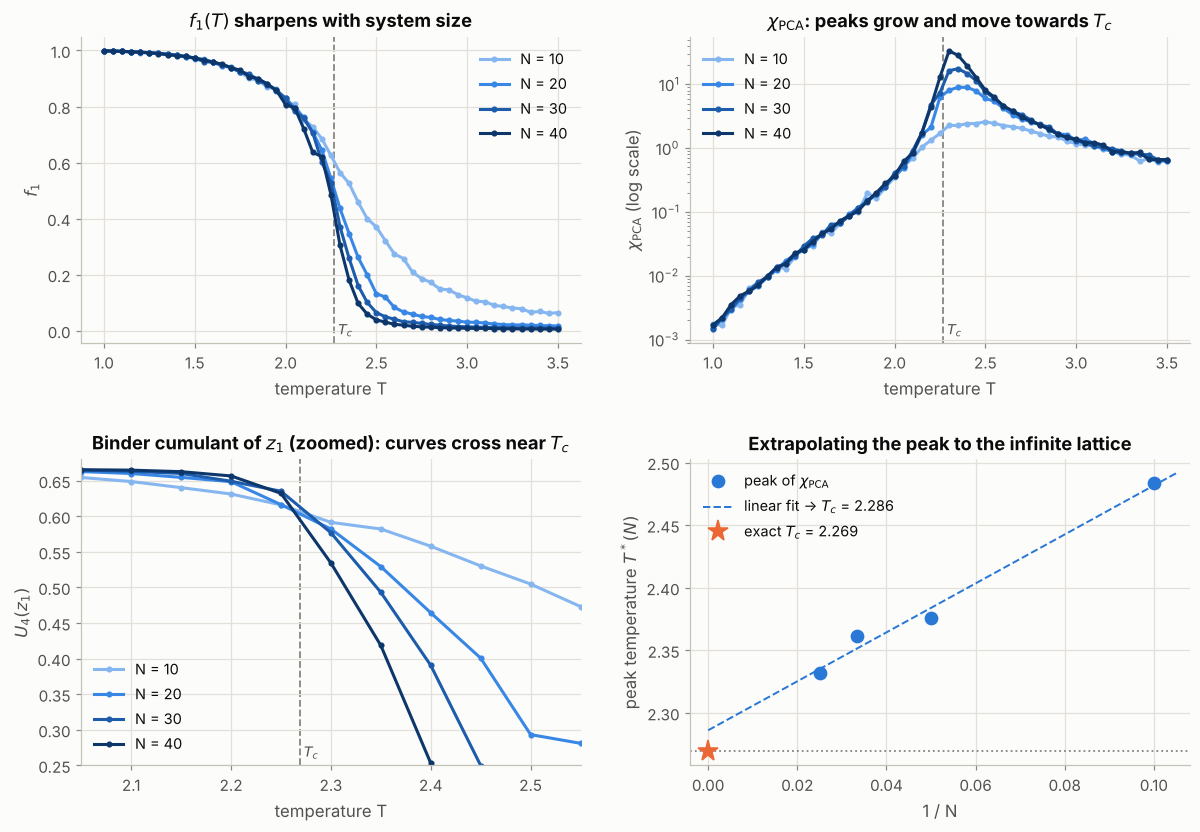

Binder crossings of U4(z1):  N=10&20: 2.252   N=20&30: 2.289   N=30&40: 2.236   N=20&40: 2.262
chi_PCA peak positions:      N=10: 2.483   N=20: 2.376   N=30: 2.361   N=40: 2.332
Extrapolated Tc from peaks: 2.286   (exact 2.269)


In [20]:
def peak_position(T, y, half_width=3):
    '''Sub-grid peak position from a parabola fitted around the maximum.'''
    i = np.argmax(y); lo, hi = max(i - half_width, 0), min(i + half_width + 1, len(T))
    a, b, _ = np.polyfit(T[lo:hi], y[lo:hi], 2)
    return -b / (2 * a)

def crossing(T, u1, u2, window=(2.0, 2.6)):
    d = u1 - u2; sel = (T >= window[0]) & (T <= window[1])
    Ts, ds = T[sel], d[sel]
    j = np.flatnonzero(np.sign(ds[:-1]) != np.sign(ds[1:]))
    if len(j) == 0: return np.nan
    j = j[0]; return Ts[j] - ds[j] * (Ts[j + 1] - Ts[j]) / (ds[j + 1] - ds[j])

fig, axes = plt.subplots(2, 2, figsize=(13, 8.6))
for Ns in SIZES:
    c = SIZE_COLORS[Ns]
    axes[0, 0].plot(TEMPS, FS[Ns]["f1"], "o-", ms=3, color=c, label=f"N = {Ns}")
    axes[0, 1].semilogy(TEMPS, FS[Ns]["chi"], "o-", ms=3, color=c, label=f"N = {Ns}")
    axes[1, 0].plot(TEMPS, FS[Ns]["U"], "o-", ms=3, color=c, label=f"N = {Ns}")
for ax in [axes[0, 0], axes[0, 1], axes[1, 0]]: tc_line(ax)   # not on the 1/N panel
axes[0, 0].set(title="$f_1(T)$ sharpens with system size", xlabel="temperature T", ylabel="$f_1$"); axes[0, 0].legend()
axes[0, 1].set(title=r"$\chi_{\mathrm{PCA}}$: peaks grow and move towards $T_c$", xlabel="temperature T", ylabel=r"$\chi_{\mathrm{PCA}}$ (log scale)"); axes[0, 1].legend()
ax = axes[1, 0]; ax.set(title="Binder cumulant of $z_1$ (zoomed): curves cross near $T_c$", xlabel="temperature T", ylabel="$U_4(z_1)$", xlim=(2.05, 2.55), ylim=(0.25, 0.68)); ax.legend(loc="lower left")

crossings = {(a, b): crossing(TEMPS, FS[a]["U"], FS[b]["U"]) for a, b in [(10, 20), (20, 30), (30, 40), (20, 40)]}
peaks = np.array([peak_position(TEMPS, FS[Ns]["chi"]) for Ns in SIZES])
invN = 1 / np.array(SIZES)
slope, Tc_fss = np.polyfit(invN, peaks, 1)
ax = axes[1, 1]
ax.plot(invN, peaks, "o", color=BLUE, ms=8, label=r"peak of $\chi_{\mathrm{PCA}}$")
xx = np.linspace(0, invN.max() * 1.05, 50); ax.plot(xx, Tc_fss + slope * xx, color=BLUE, lw=1.3, ls="--", label=f"linear fit → $T_c$ = {Tc_fss:.3f}")
ax.axhline(TC, color=MUTED, lw=1.2, ls=":"); ax.plot(0, TC, "*", color=ORANGE, ms=14, label=f"exact $T_c$ = {TC:.3f}")
ax.set(title="Extrapolating the peak to the infinite lattice", xlabel="1 / N", ylabel=r"peak temperature $T^*(N)$", xlim=(-0.004, invN.max() * 1.08)); ax.legend(loc="upper left")
fig.subplots_adjust(hspace=0.38, wspace=0.22); save(fig, "15_finite_size"); plt.show()

print("Binder crossings of U4(z1):  " + "   ".join(f"N={a}&{b}: {v:.3f}" for (a, b), v in crossings.items()))
print("chi_PCA peak positions:      " + "   ".join(f"N={n}: {p:.3f}" for n, p in zip(SIZES, peaks)))
print(f"Extrapolated Tc from peaks: {Tc_fss:.3f}   (exact {TC:.3f})")

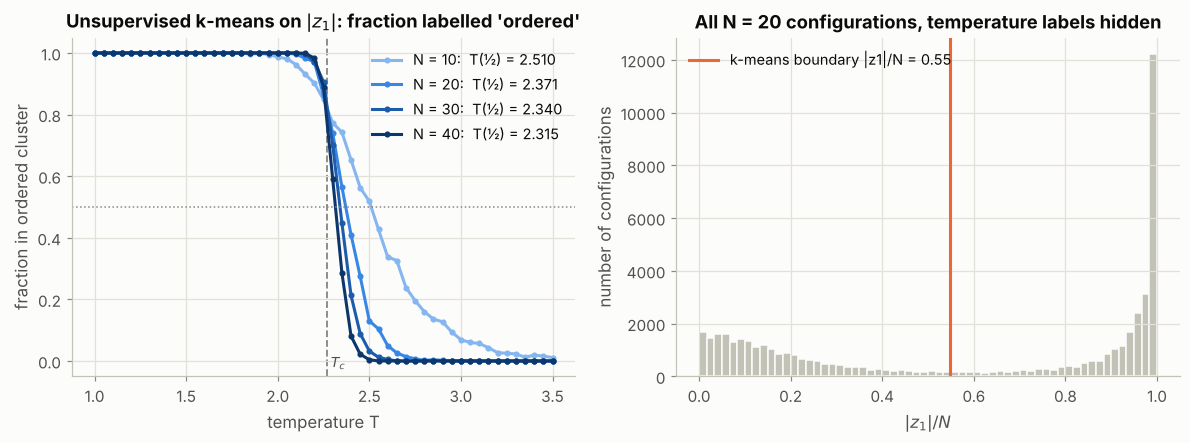

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.0))
Tc_km = {}
for Ns in SIZES:
    feat = (np.abs(FS[Ns]["z1"]) / Ns).reshape(-1, 1)
    km = KMeans(n_clusters=2, n_init=10, random_state=0).fit(feat)
    ordered_label = np.argmax(km.cluster_centers_.ravel())
    frac = (km.labels_ == ordered_label).reshape(nT, -1).mean(1)
    j = np.flatnonzero((frac[:-1] >= 0.5) & (frac[1:] < 0.5))[0]
    Tc_km[Ns] = TEMPS[j] + (frac[j] - 0.5) / (frac[j] - frac[j + 1]) * (TEMPS[j + 1] - TEMPS[j])
    axes[0].plot(TEMPS, frac, "o-", ms=3, color=SIZE_COLORS[Ns], label=f"N = {Ns}:  T(½) = {Tc_km[Ns]:.3f}")
axes[0].axhline(0.5, color=MUTED, lw=1, ls=":"); tc_line(axes[0])
axes[0].set(title="Unsupervised k-means on $|z_1|$: fraction labelled 'ordered'", xlabel="temperature T", ylabel="fraction in ordered cluster"); axes[0].legend()

ax = axes[1]
z = FS[20]["z1"].ravel() / 20
km20 = KMeans(n_clusters=2, n_init=10, random_state=0).fit(np.abs(z).reshape(-1, 1))
thr = km20.cluster_centers_.ravel().mean()
ax.hist(np.abs(z), bins=60, color=AXIS, edgecolor=SURFACE)
ax.axvline(thr, color=ORANGE, lw=2, label=f"k-means boundary |z1|/N = {thr:.2f}")
ax.set(title="All N = 20 configurations, temperature labels hidden", xlabel="$|z_1|/N$", ylabel="number of configurations"); ax.legend()
save(fig, "16_unsupervised_classification"); plt.show()

In [22]:
summary = [("Binder crossing U4(z1), N=30 & 40", crossings[(30, 40)]),
           ("Binder crossing U4(z1), N=20 & 40", crossings[(20, 40)]),
           ("chi_PCA peak, extrapolated 1/N -> 0", Tc_fss),
           ("k-means half-point, N = 40", Tc_km[40]),
           ("chi' peak, N = 20 (single size)", peak_position(TEMPS, chi_p))]
print(f"{'Estimator':42s} {'Tc':>7s} {'error':>8s}")
for name, v in summary:
    print(f"{name:42s} {v:7.3f} {100*(v-TC)/TC:+7.1f}%")
print(f"{'Exact (Onsager)':42s} {TC:7.3f}")

Estimator                                       Tc    error
Binder crossing U4(z1), N=30 & 40            2.236    -1.5%
Binder crossing U4(z1), N=20 & 40            2.262    -0.3%
chi_PCA peak, extrapolated 1/N -> 0          2.286    +0.7%
k-means half-point, N = 40                   2.315    +2.0%
chi' peak, N = 20 (single size)              2.376    +4.7%
Exact (Onsager)                              2.269


**What to notice.** As $N$ grows, $f_1(T)$ becomes steeper, the susceptibility peak grows (in the infinite system it diverges) and moves towards $T_c$, and the Binder curves of $z_1$ cross close to the exact value. The k-means half-point also drifts down towards $T_c$ with increasing $N$. Combining several sizes, **PCA alone locates the transition to within one to two percent**, with no physical input other than the raw spin configurations. The individual Binder crossings scatter by a few hundredths because the curves meet at a shallow angle and each point carries statistical noise from 1000 configurations; longer runs would tighten them.

## 9. Answers to the project questions

**1. How does the structure of the spin configurations change as the temperature crosses the critical region?**
Below $T_c$ the configurations are almost uniformly magnetised, in either the $+$ or the $-$ state, with isolated flipped spins; the correlation function $G(r)$ saturates at $m_0^2$, indicating long-range order. At $T_c$ clusters of all sizes coexist and $G(r)$ decays as a power law, $r^{-1/4}$, since the correlation length is limited only by the lattice size. Above $T_c$ the configurations are short-range correlated noise and $G(r)$ decays exponentially.

**2. What fraction of the variance is captured by the first few principal components?**
In the global PCA of all temperatures, the first component carries about half of the total variance, and components 2–5 form a near-degenerate group of about 1% each. The rest is spread thinly over the remaining ~395 directions. The degeneracy follows from translational invariance: the covariance matrix is diagonalised by Fourier modes, with $\mathbf v_1$ the $\mathbf k=0$ mode and $\mathbf v_{2\text{–}5}$ the four smallest non-zero wavevectors. Within a single temperature, the first component carries nearly all the variance below $T_c$ ($f_1\to1$), but only a few percent above it.

**3. How does the first principal component change with temperature?**
The direction $\mathbf v_1$ is uniform, so $z_1=Nm$: the first component *is* the magnetisation. What changes with temperature is its distribution and weight. $f_1(T)\approx\langle m^2\rangle$ falls from about 1 to about 0.02, most steeply near $T_c$, and $P(z_1)$ changes from bimodal (peaks at $\pm N m_0$) to broad and flat near $T_c$, to a narrow Gaussian centred on zero.

**4. Do the projections onto the first one or two principal components distinguish ordered and disordered configurations?**
Yes. In the $(z_1,z_2)$ plane, ordered configurations form two clusters at $z_1\approx\pm N$, disordered ones form a single compact cluster at the origin, and critical configurations lie on the bridge between them with the largest spread in $z_2$. A two-cluster k-means on $|z_1|$, applied without temperature labels, classifies configurations into ordered and disordered with a boundary that converges towards $T_c$ as $N$ increases.

**5. How does the PCA analysis compare with the conventional magnetisation and susceptibility?**
They are equivalent at the level of the first component: $\langle|z_1|\rangle/N=\langle|m|\rangle$, $f_1\approx\langle m^2\rangle$, and the variance of $z_1$ reproduces the susceptibility exactly. PCA adds information in $f_2(T)$, which peaks in the same critical window as $\chi'$ because long-wavelength fluctuations are strongest there. Two caveats: PCA needs both symmetry-broken states in the data to detect order, and the textbook $\chi$ with $\langle m\rangle$ must be replaced by $\chi'$ with $\langle|m|\rangle$ for a finite, symmetrically sampled system.

**6. Can PCA provide a useful data-driven signature of the phase transition?**
Yes. Without being told about energy, magnetisation or temperature, PCA finds the order parameter as its leading component, and its explained-variance ratio and projection statistics locate the transition. Using finite-size scaling (Binder crossing of $z_1$ and extrapolation of the $\chi_{\text{PCA}}$ peak), the estimated $T_c$ agrees with the exact $2.269$ to within one to two percent. The limitation is that PCA is linear: it succeeds here because the Ising order parameter is a linear function of the spins. For transitions whose order parameter is non-linear, or for topological transitions such as the XY model's BKT transition, PCA's leading components can fail, and non-linear methods (kernel PCA, autoencoders, t-SNE) are needed.

## 10. Limitations, extensions, and presentation material

### 10.1 Limitations
- **Linear method.** PCA can only find order parameters that are linear in the spins; it works for Ising because $m$ is linear.
- **Symmetric sampling is required.** If the data contain only one ordered state, $f_1$ no longer signals order (§6.2).
- **Finite-size effects.** For a single size, every signature is rounded and shifted above $T_c$; several sizes are needed for a precise estimate.
- **Critical slowing down.** Metropolis samples near $T_c$ are correlated ($\tau_{\text{int}}$ grows rapidly), so error bars there are larger than the raw sample count suggests.

### 10.2 Natural extensions
Wolff cluster updates to remove critical slowing down; the antiferromagnetic Ising model (PCA finds the staggered magnetisation, a checkerboard $\mathbf v_1$); kernel PCA or an autoencoder; supervised learning (logistic regression or a small neural network trained on $T\ll T_c$ and $T\gg T_c$, then applied near $T_c$).

### 10.3 Suggested slide outline (10–12 slides)
1. Title and motivation: can unsupervised learning find a phase transition?
2. The 2D Ising model, order parameter, $T_c$ — snapshots (`04_snapshots.png`)
3. Metropolis and validation — `01_equilibration.png`, `03_validation.png`
4. PCA in one slide: covariance, eigenvectors, $f_k$
5. Scree plot and principal directions — `06_scree_plot.png`, `07_principal_directions.png`
6. Key result: $z_1 = Nm$ — `08_z1_vs_magnetisation.png`
7. The PCA map — `09_pca_scatter.png`
8. $f_1(T)$, $f_2(T)$ and the symmetry experiment — `10_f1_f2_vs_T.png`
9. $P(z_1)$ and the pitchfork — `11_P_z1_histograms.png`, `12_P_z1_heatmap.png`
10. Comparison with physics — `13_conventional_observables.png`, `14_pca_vs_physics.png`
11. Finite-size scaling and $T_c$ estimate — `15_finite_size.png`, `16_unsupervised_classification.png`
12. Conclusions and limitations

### 10.4 Likely viva questions, with short answers
- *Why centre the data?* PCA diagonalises the covariance; without centring, the first component would point at the mean rather than along the direction of greatest variation.
- *Why is $\mathbf v_1$ uniform?* Translation invariance makes the covariance circulant, diagonalised by Fourier modes; the $\mathbf k=0$ mode has the largest eigenvalue because ferromagnetic correlations are strongest at long wavelengths.
- *Why are $\lambda_2\ldots\lambda_5$ equal?* Square-lattice symmetry: $(\pm2\pi/N,0)$ and $(0,\pm2\pi/N)$ have the same $|\mathbf k|$, each with a cosine and a sine.
- *Why does the susceptibility peak lie above $T_c$ for finite $N$?* The correlation length is capped at $\sim N$, so the maximum of the fluctuations occurs where $\xi(T)\approx N$, which is slightly above $T_c$; the shift scales as $N^{-1/\nu}=N^{-1}$.
- *Why start chains ordered with random signs?* Below $T_c$ a single Metropolis chain cannot tunnel between $\pm m$, and random starts can freeze into striped domain states; ordered random-sign starts give equilibrium samples from both symmetric states.
- *What does detailed balance guarantee?* That the Boltzmann distribution is a stationary distribution of the Markov chain; with ergodicity, the chain converges to it.

### 10.5 References
1. L. Onsager, *Phys. Rev.* **65**, 117 (1944) — exact solution; C. N. Yang, *Phys. Rev.* **85**, 808 (1952) — spontaneous magnetisation.
2. M. E. J. Newman and G. T. Barkema, *Monte Carlo Methods in Statistical Physics* (Oxford, 1999).
3. L. Wang, "Discovering phase transitions with unsupervised learning," *Phys. Rev. B* **94**, 195105 (2016).
4. W. Hu, R. R. P. Singh, R. T. Scalettar, "Discovering phases, phase transitions, and crossovers through unsupervised machine learning," *Phys. Rev. E* **95**, 062122 (2017).